In [1]:
# Data Cleaning and Visualization Project

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
data = {
    'Order_ID': [101, 102, 103, 104, 105, 106, 107, 108, 109, 109],
    'Product': ['Laptop', 'Phone', 'Tablet', 'Laptop', 'Phone',
                'Tablet', 'Laptop', 'Phone', 'Tablet', 'Tablet'],
    'Category': ['Electronics', 'Electronics', 'Electronics',
                 'Electronics', 'Electronics', 'Electronics',
                 'Electronics', 'Electronics', 'Electronics', 'Electronics'],
    'Quantity': [2, 3, 1, 2, np.nan, 4, 2, 3, 1, 1],
    'Price': [50000, 20000, 15000, 50000, 20000, 15000,
              50000, 20000, 15000, 15000],
    'Sales': [100000, 60000, 15000, 100000, 40000,
              60000, 100000, 60000, 15000, 15000]
}

df = pd.DataFrame(data)

df

,Order_ID,Product,Category,Quantity,Price,Sales
0,101,Laptop,Electronics,2.0,50000,100000
1,102,Phone,Electronics,3.0,20000,60000
2,103,Tablet,Electronics,1.0,15000,15000
3,104,Laptop,Electronics,2.0,50000,100000
4,105,Phone,Electronics,NaN,20000,40000
5,106,Tablet,Electronics,4.0,15000,60000
6,107,Laptop,Electronics,2.0,50000,100000
7,108,Phone,Electronics,3.0,20000,60000
8,109,Tablet,Electronics,1.0,15000,15000
9,109,Tablet,Electronics,1.0,15000,15000


In [3]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nFirst Five Rows:")
display(df.head())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (10, 6)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Order_ID  10 non-null     int64  
 1   Product   10 non-null     object 
 2   Category  10 non-null     object 
 3   Quantity  9 non-null      float64
 4   Price     10 non-null     int64  
 5   Sales     10 non-null     int64  
dtypes: float64(1), int64(3), object(2)
memory usage: 612.0+ bytes

First Five Rows:


,Order_ID,Product,Category,Quantity,Price,Sales
0,101,Laptop,Electronics,2.0,50000,100000
1,102,Phone,Electronics,3.0,20000,60000
2,103,Tablet,Electronics,1.0,15000,15000
3,104,Laptop,Electronics,2.0,50000,100000
4,105,Phone,Electronics,NaN,20000,40000



Missing Values:
Order_ID    0
Product     0
Category    0
Quantity    1
Price       0
Sales       0
dtype: int64

Duplicate Rows: 1

Statistical Summary:


,Order_ID,Quantity,Price,Sales
count,10.000000,9.000000,10.000000,10.000000
mean,105.400000,2.111111,27000.000000,56500.000000
std,2.875181,1.054093,16020.819788,35201.799196
min,101.000000,1.000000,15000.000000,15000.000000
25%,103.250000,1.000000,15000.000000,21250.000000
50%,105.500000,2.000000,20000.000000,60000.000000
75%,107.750000,3.000000,42500.000000,90000.000000
max,109.000000,4.000000,50000.000000,100000.000000


In [6]:

# Check missing values before cleaning
print("Missing values before cleaning:")
print(df.isnull().sum())

# Fill missing Quantity with the median
df['Quantity'] = df['Quantity'].fillna(df['Quantity'].median())

# Verify missing values
print("\nMissing values after cleaning:")
print(df.isnull().sum())



Missing values before cleaning:
Order_ID    0
Product     0
Category    0
Quantity    1
Price       0
Sales       0
dtype: int64

Missing values after cleaning:
Order_ID    0
Product     0
Category    0
Quantity    0
Price       0
Sales       0
dtype: int64


In [7]:

# Count duplicate rows before cleaning
print("Duplicates before cleaning:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Check the result
print("Duplicates after cleaning:", df.duplicated().sum())

# Display the cleaned dataset
display(df)



Duplicates before cleaning: 1
Duplicates after cleaning: 0


,Order_ID,Product,Category,Quantity,Price,Sales
0,101,Laptop,Electronics,2.0,50000,100000
1,102,Phone,Electronics,3.0,20000,60000
2,103,Tablet,Electronics,1.0,15000,15000
3,104,Laptop,Electronics,2.0,50000,100000
4,105,Phone,Electronics,2.0,20000,40000
5,106,Tablet,Electronics,4.0,15000,60000
6,107,Laptop,Electronics,2.0,50000,100000
7,108,Phone,Electronics,3.0,20000,60000
8,109,Tablet,Electronics,1.0,15000,15000


In [8]:

# Calculate the first and third quartiles
Q1 = df['Sales'].quantile(0.25)
Q3 = df['Sales'].quantile(0.75)

# Calculate the interquartile range
IQR = Q3 - Q1

# Define lower and upper limits
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

# Identify potential outliers
outliers = df[
    (df['Sales'] < lower_limit) |
    (df['Sales'] > upper_limit)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

print("\nPotential outliers:")
display(outliers)




Q1: 40000.0
Q3: 100000.0
IQR: 60000.0
Lower limit: -50000.0
Upper limit: 190000.0

Potential outliers:


,Order_ID,Product,Category,Quantity,Price,Sales


In [9]:

print("Cleaned Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nCleaned Dataset:")
display(df)



Cleaned Dataset Shape: (9, 6)

Missing Values:
Order_ID    0
Product     0
Category    0
Quantity    0
Price       0
Sales       0
dtype: int64

Duplicate Rows:
0

Cleaned Dataset:


,Order_ID,Product,Category,Quantity,Price,Sales
0,101,Laptop,Electronics,2.0,50000,100000
1,102,Phone,Electronics,3.0,20000,60000
2,103,Tablet,Electronics,1.0,15000,15000
3,104,Laptop,Electronics,2.0,50000,100000
4,105,Phone,Electronics,2.0,20000,40000
5,106,Tablet,Electronics,4.0,15000,60000
6,107,Laptop,Electronics,2.0,50000,100000
7,108,Phone,Electronics,3.0,20000,60000
8,109,Tablet,Electronics,1.0,15000,15000


In [10]:

# Basic Sales Analysis

print("========== SALES ANALYSIS ==========")

# Total sales
total_sales = df['Sales'].sum()
print("Total Sales:", total_sales)

# Average sales
average_sales = df['Sales'].mean()
print("Average Sales:", round(average_sales, 2))

# Highest sales
highest_sales = df['Sales'].max()
print("Highest Sales:", highest_sales)

# Lowest sales
lowest_sales = df['Sales'].min()
print("Lowest Sales:", lowest_sales)

# Total quantity sold
total_quantity = df['Quantity'].sum()
print("Total Quantity Sold:", total_quantity)

# Sales by product
product_sales = df.groupby('Product')['Sales'].sum()

print("\nTotal Sales by Product:")
display(product_sales)



========== SALES ANALYSIS ==========
Total Sales: 550000
Average Sales: 61111.11
Highest Sales: 100000
Lowest Sales: 15000
Total Quantity Sold: 20.0

Total Sales by Product:


Product
Laptop    300000
Phone     160000
Tablet     90000
Name: Sales, dtype: int64

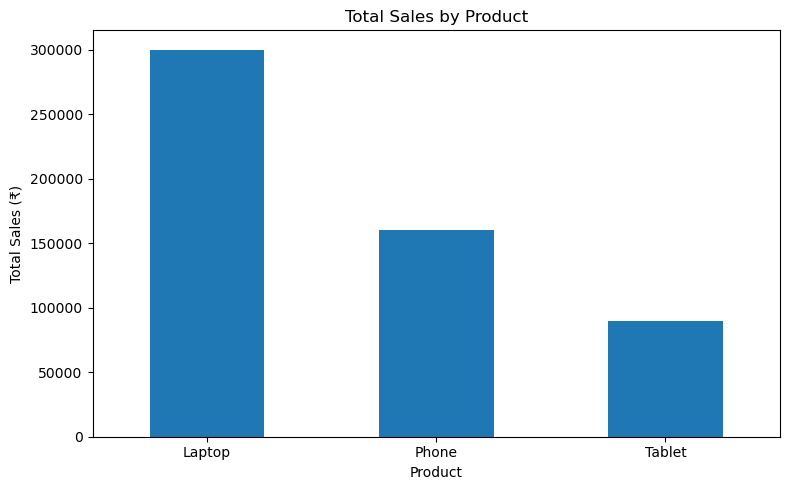

In [21]:

# Calculate sales by product
product_sales = df.groupby('Product')['Sales'].sum()

# Create bar chart
plt.figure(figsize=(8, 5))
product_sales.plot(kind='bar')

plt.title('Total Sales by Product')
plt.xlabel('Product')
plt.ylabel('Total Sales (₹)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('sales_chart.png', dpi=300, bbox_inches='tight')
plt.show()



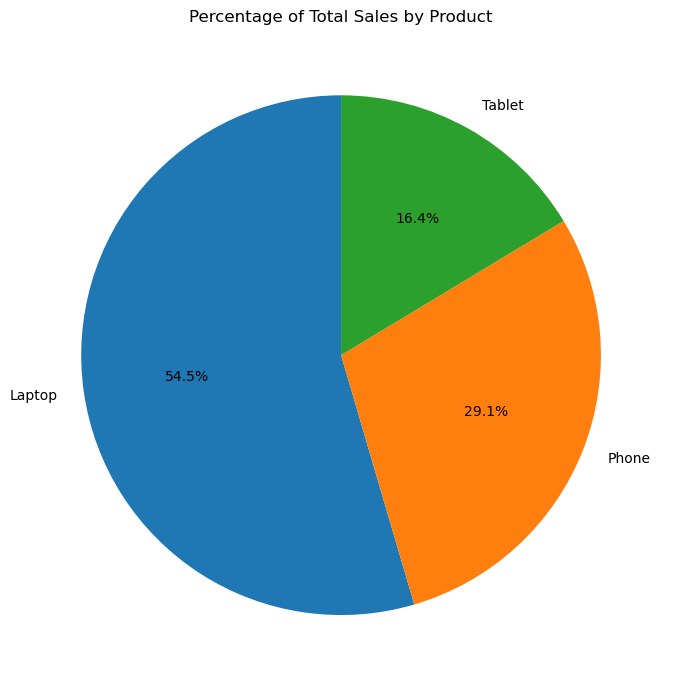

In [20]:

# Calculate total sales by product
product_sales = df.groupby('Product')['Sales'].sum()

# Create pie chart
plt.figure(figsize=(7, 7))

plt.pie(
    product_sales,
    labels=product_sales.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Percentage of Total Sales by Product')
plt.tight_layout()
plt.savefig('sales_chart.png', dpi=300, bbox_inches='tight')
plt.show()



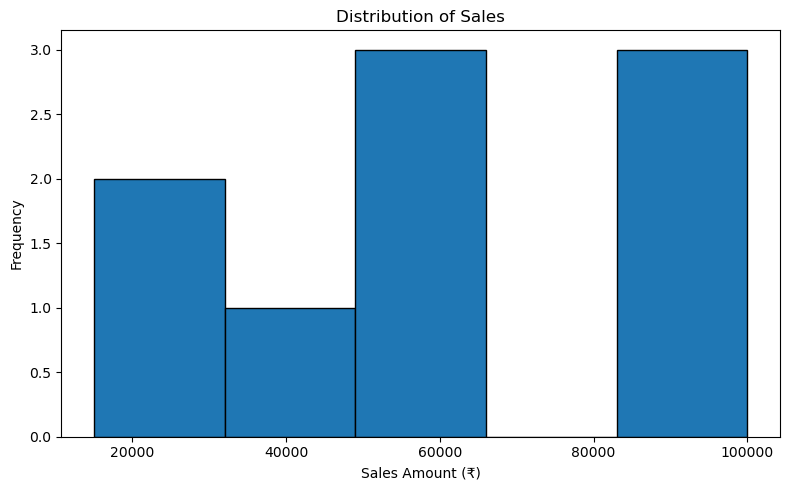

In [19]:

plt.figure(figsize=(8, 5))

plt.hist(df['Sales'], bins=5, edgecolor='black')

plt.title('Distribution of Sales')
plt.xlabel('Sales Amount (₹)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.savefig('sales_chart.png', dpi=300, bbox_inches='tight')
plt.show()



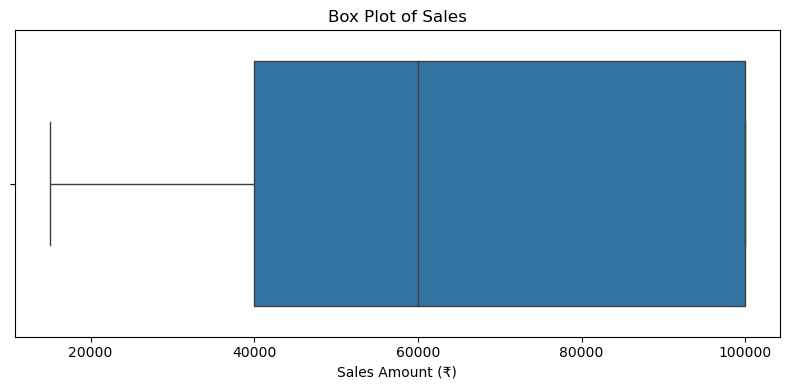

In [18]:

plt.figure(figsize=(8, 4))

sns.boxplot(x=df['Sales'])

plt.title('Box Plot of Sales')
plt.xlabel('Sales Amount (₹)')

plt.tight_layout()
plt.savefig('sales_chart.png', dpi=300, bbox_inches='tight')
plt.show()



In [16]:

# Save the cleaned dataset
df.to_csv('cleaned_sales_data.csv', index=False)

print("Cleaned dataset saved successfully!")



Cleaned dataset saved successfully!
